# Importing libraries and reading data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import joblib


In [2]:
sns.set_theme(style='ticks', palette='colorblind', context='notebook')

In [3]:
df= pd.read_csv(r"C:\Users\MINE\Desktop\Customer Segmentation\data\customer_segmentation.csv")

# Data inspection and Cleaning

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [7]:
df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [8]:
today= dt.datetime.now().date()
df['age']= today.year - df['Year_Birth']

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,0,0,0,3,11,0,45


In [10]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
age                     0
dtype: int64

In [11]:
df.dropna(inplace=True)

In [12]:
df.duplicated().sum()

0

In [13]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], dayfirst=True)

In [14]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,0,3,11,0,45


In [15]:
df['Children']= df['Kidhome'] + df['Teenhome']
df['amount_spent']= df['MntFishProducts'] + df['MntFruits'] + df['MntGoldProds']+ df['MntSweetProducts'] + df['MntWines'] + df['MntMeatProducts']
df['campaign']= df['AcceptedCmp1'] + df['AcceptedCmp2'] + df['AcceptedCmp3']+ df['AcceptedCmp4'] + df['AcceptedCmp5']


In [16]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,3,11,1,69,0,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,3,11,0,72,2,27,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,3,11,0,61,0,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,3,11,0,42,1,53,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,3,11,0,45,1,422,0


# EDA and Data visualization

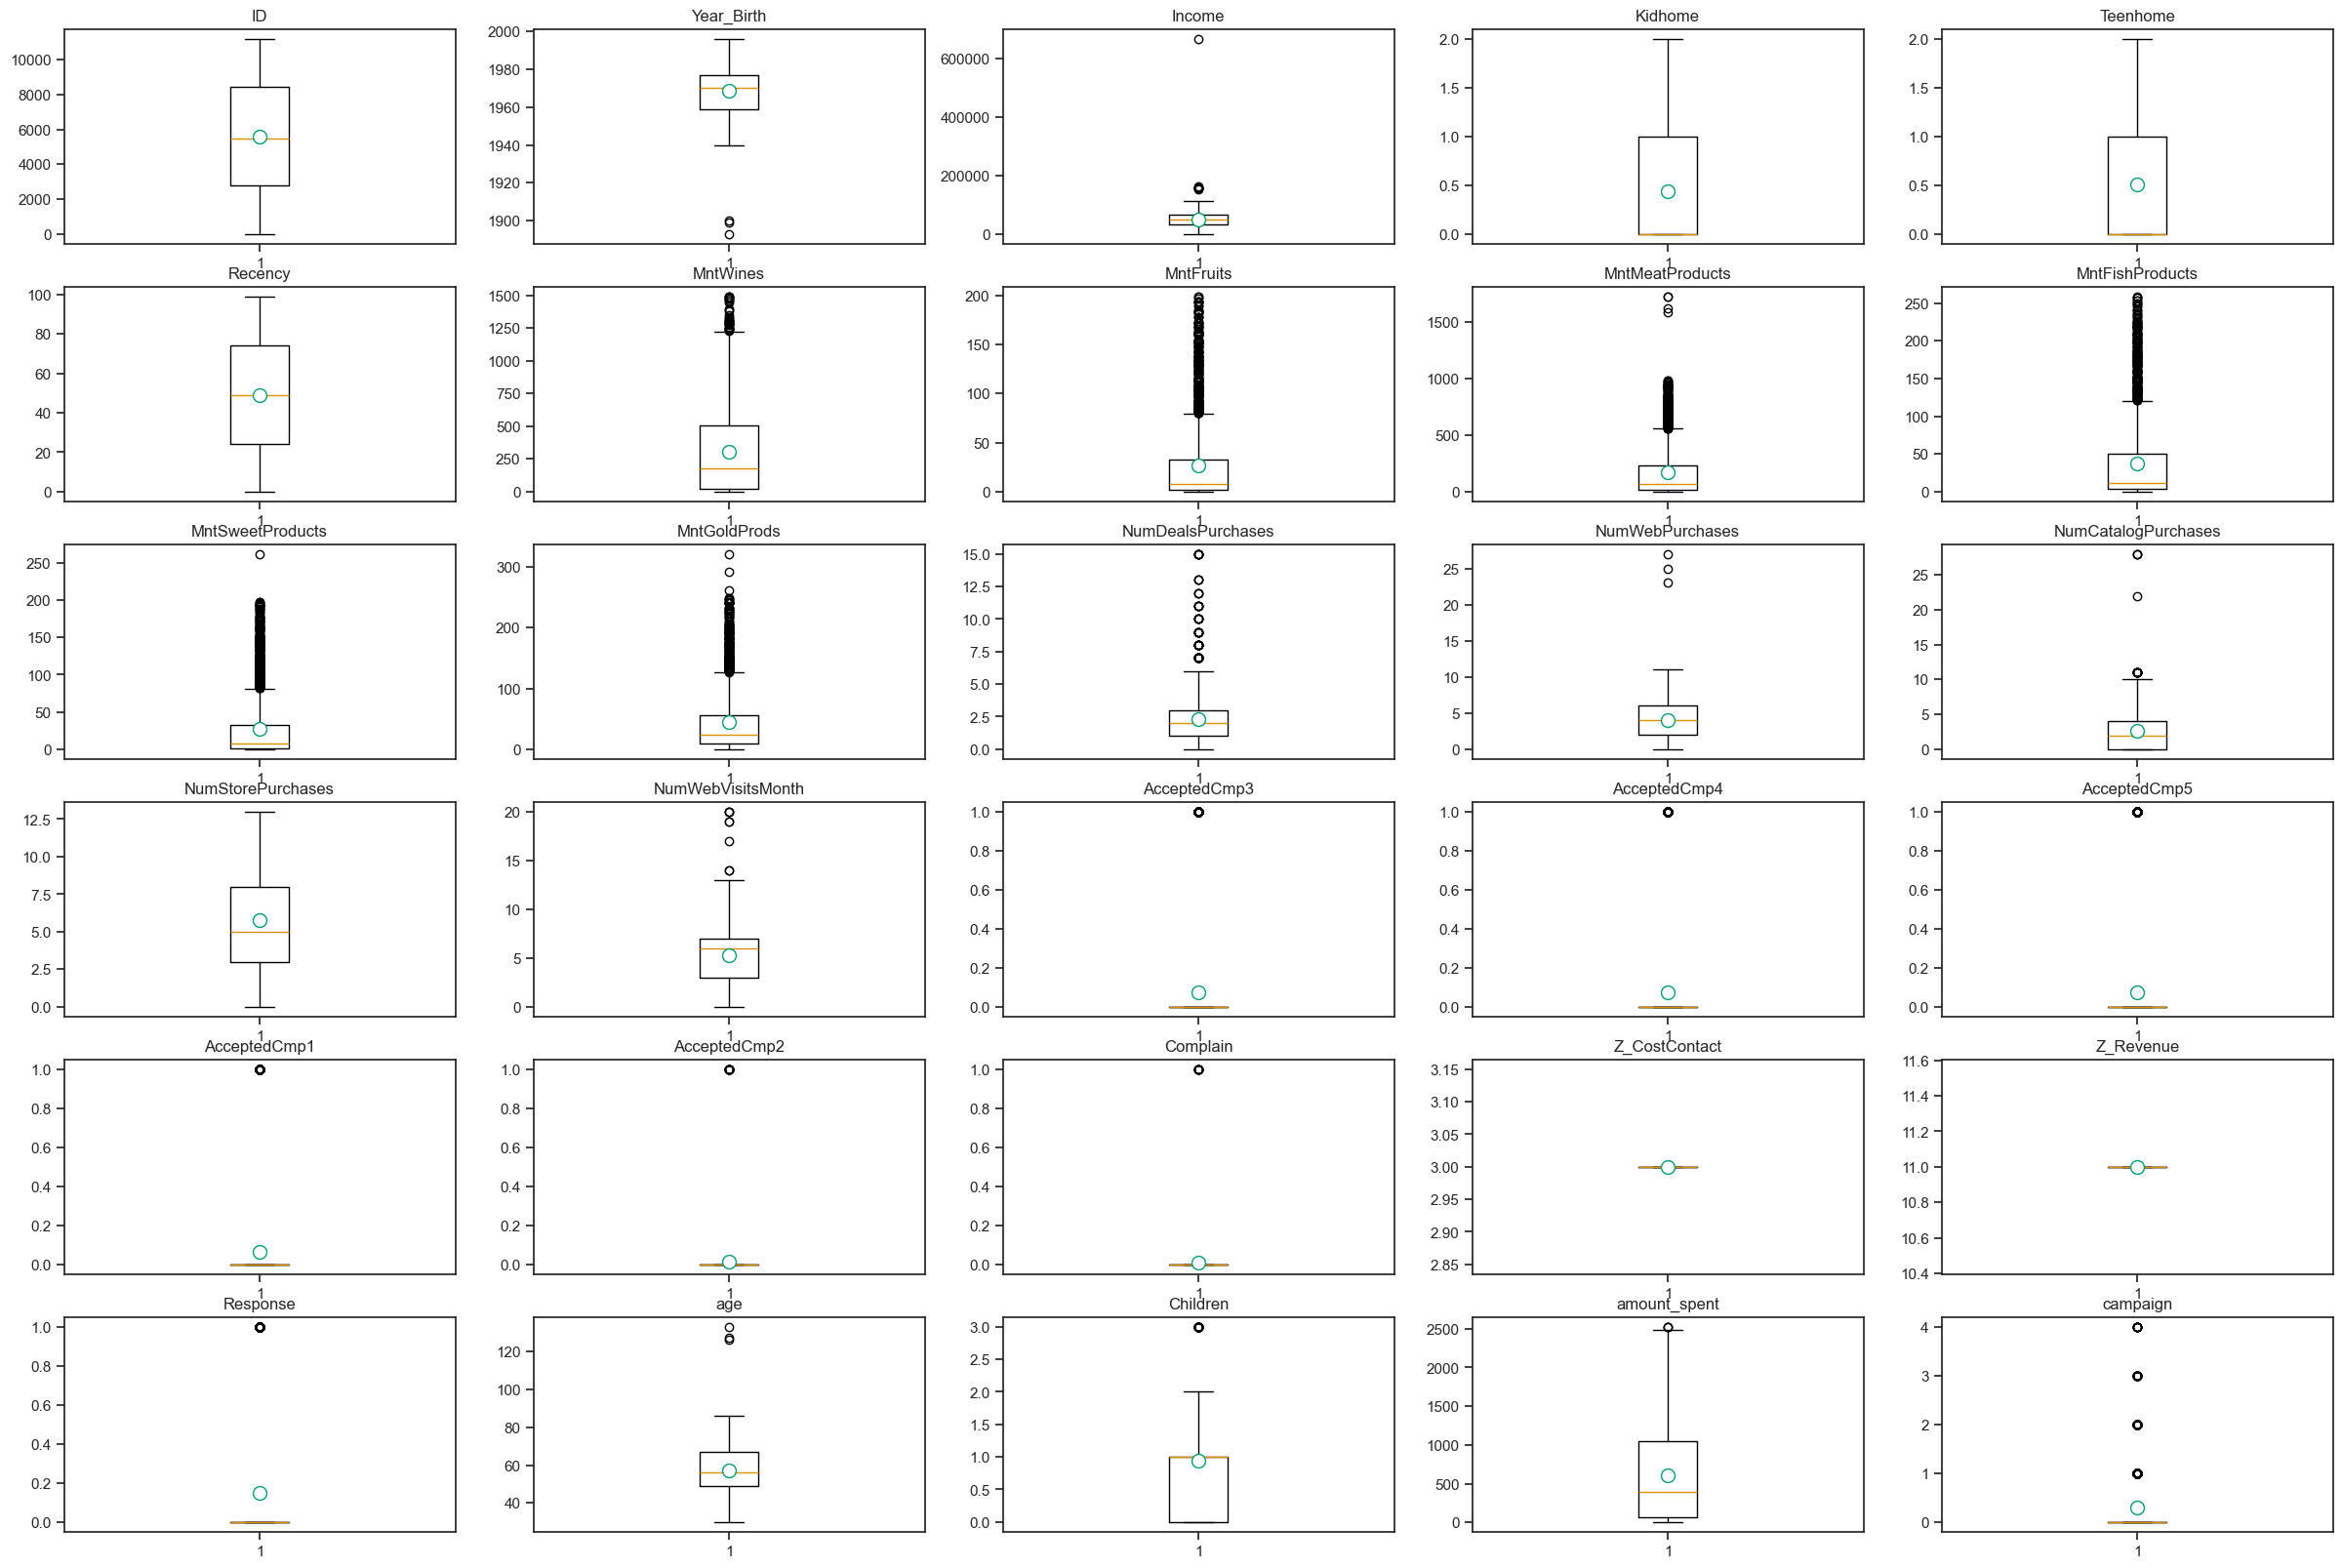

In [17]:

# Visualizing Distributions

fig,axes= plt.subplots(ncols=5,nrows=6, figsize= (30,20))
axes= axes.reshape(-1)
for i,col in enumerate(df.select_dtypes(include=np.number)):
    axes[i].boxplot(df[col],showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
    axes[i].set_title(col)

plt.show()
    

* A lot of people were born between 1960 and 1980
* Most people earn less than 200000, with a few Exceptions which can be considered as outliers
* A lot od people have just 1 kid
* The amount spent are mnt columns are mostly skewed to the right
* A lot of people spend between 500 and 1000
* Most people do not accept campaign and they dont give complaints

In [18]:
# Fixing outliers

def outlier(col, df):
  Q1= df[col].quantile(0.25)
  Q3= df[col].quantile(0.75)
  IQR= Q3 - Q1
  upper_limit= Q3 + 1.5 * IQR
  lower_limit= Q1- 1.5 * IQR
  df[col]= df[col].where((df[col] <= upper_limit ) & (df[col]>= lower_limit), df[col].median())

In [19]:
outlier('Income', df)

In [20]:
outlier('age', df)

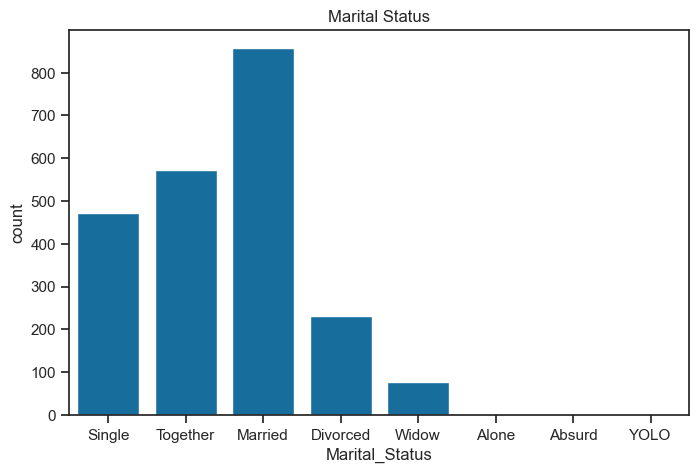

In [21]:
plt.figure(figsize=(8,5))
sns.countplot(data= df, x= 'Marital_Status')


plt.title('Marital Status')
plt.show()

> Most people in the distribution are married, together comes second and there a significant number of single people also

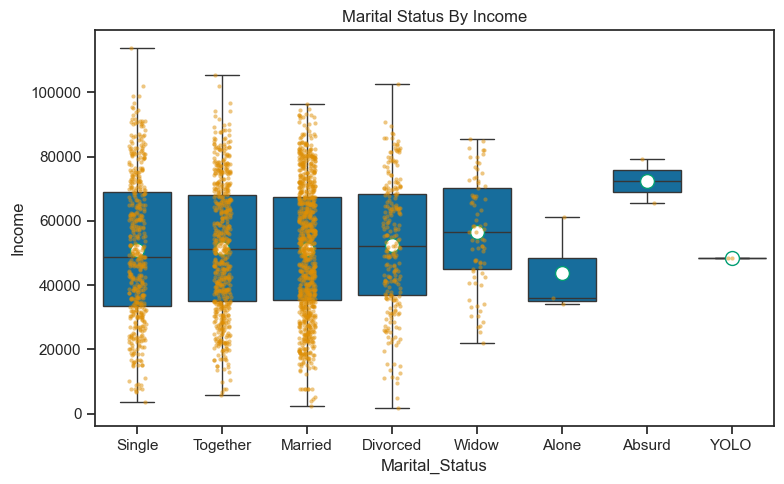

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Marital_Status', y='Income', data=df,showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
sns.stripplot(x='Marital_Status', y='Income', data=df,alpha=0.5,size=3,jitter=True)

plt.title('Marital Status By Income')
plt.tight_layout()
plt.show()

> People married and together tends to spend a lot, followed by single people

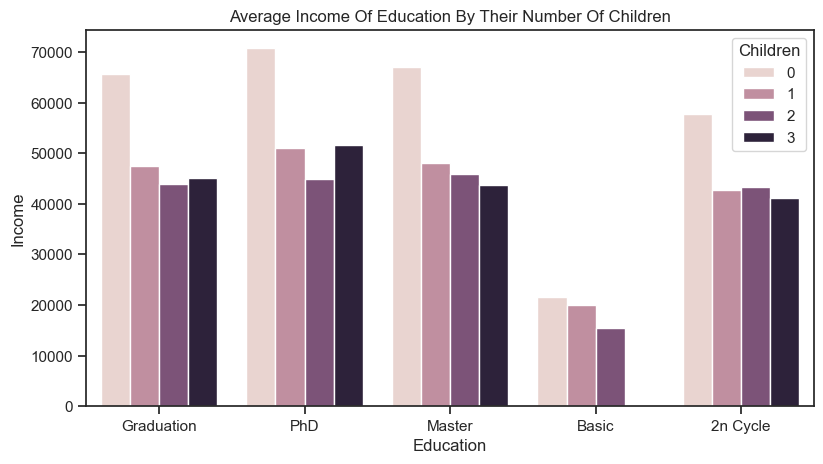

In [23]:
plt.figure(figsize=(8.4,4.6))

sns.barplot(data= df, x='Education', y='Income', estimator='mean', hue='Children',errorbar=None)

plt.tight_layout()
plt.title('Average Income Of Education By Their Number Of Children')
plt.show()

> People with 0 children tends to earn more, People with basic education earns the lowest

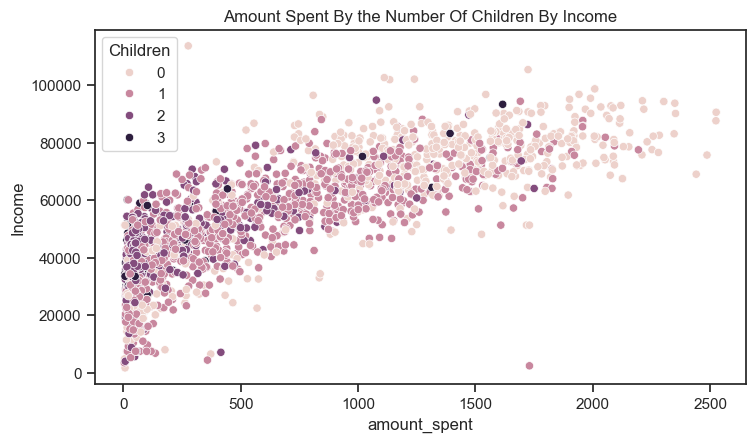

In [24]:
plt.figure(figsize=(8.4,4.6))

sns.scatterplot(data=df, y='Income', x='amount_spent', hue= 'Children',)
plt.title('Amount Spent By the Number Of Children By Income')

plt.show()

> Strong linear relationship between income and amount spent i.e people that earn more thends to spend more.
> Children also influence spending habit, people with 0 kids spends more with people with 1 following suit

In [25]:
df.Income.describe()

count      2216.000000
mean      51632.727888
std       20675.942580
min        1730.000000
25%       35303.000000
50%       51377.250000
75%       68179.500000
max      113734.000000
Name: Income, dtype: float64

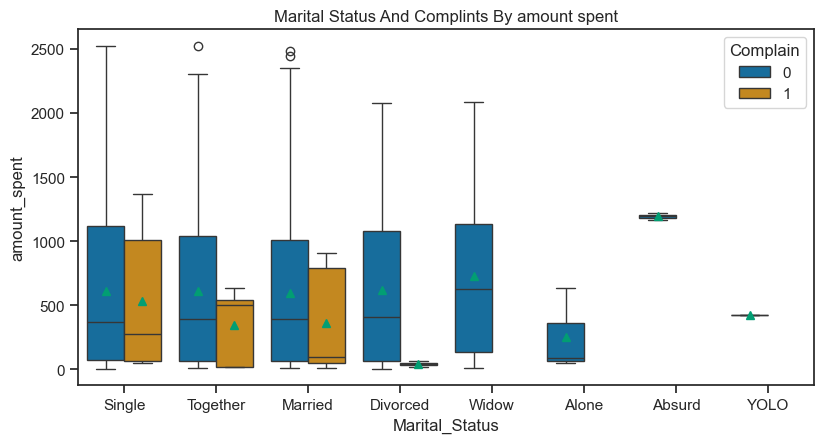

In [30]:
plt.figure(figsize=(8.4,4.6))

sns.boxplot(data=df, x='Marital_Status', y='amount_spent', hue='Complain',showmeans=True)

plt.title('Marital Status And Complints By amount spent')
plt.tight_layout()
plt.show()

> People who don't make complaints spends the most

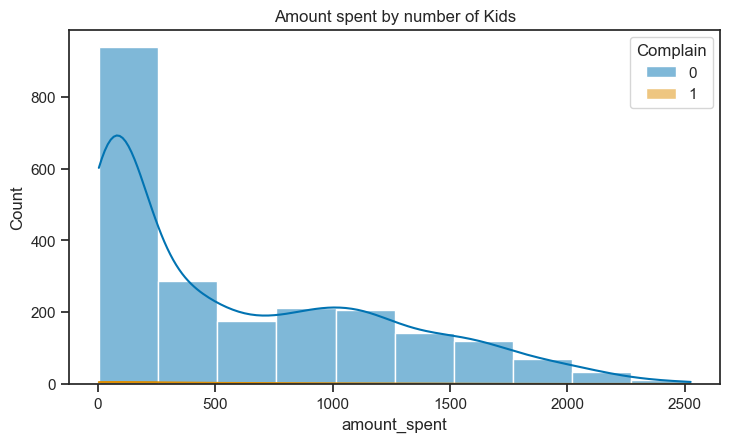

In [31]:
plt.figure(figsize=(8.4,4.6))

sns.histplot(data= df, hue= 'Complain', x='amount_spent', bins=10, kde= True)

plt.title('Amount spent by number of Kids')

plt.show()

> A lot of people spend between 0 and 500

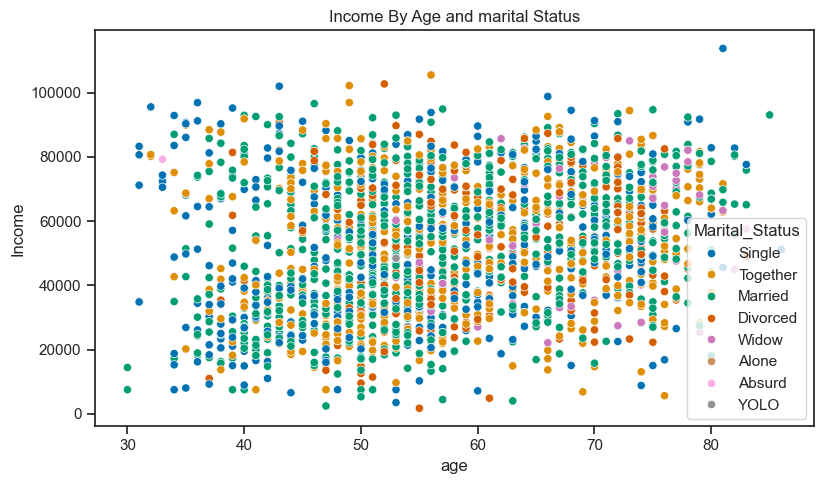

In [32]:
plt.figure(figsize=(8.4,5))

sns.scatterplot(data=df, x='age', y= 'Income', hue='Marital_Status')


plt.title('Income By Age and marital Status')
plt.tight_layout()
plt.show()

> Age and Marital Status Does not really influence income

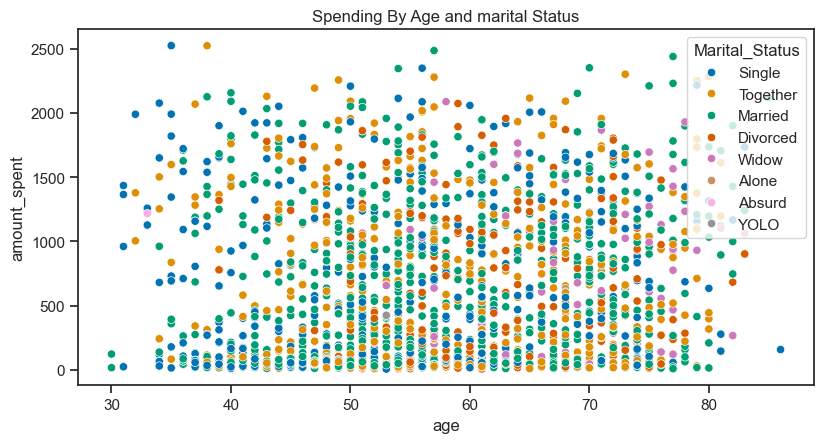

In [33]:
plt.figure(figsize=(8.4,4.6))


sns.scatterplot(data=df, x='age', y= 'amount_spent', hue='Marital_Status')
plt.title('Spending By Age and marital Status')
plt.tight_layout()
plt.show()

> Age does not really influence spending habit, but a lot of top spenders are married, single or together

In [34]:
df[ 'Year_Birth'].value_counts().head()

Year_Birth
1976    89
1971    86
1975    83
1972    78
1978    76
Name: count, dtype: int64

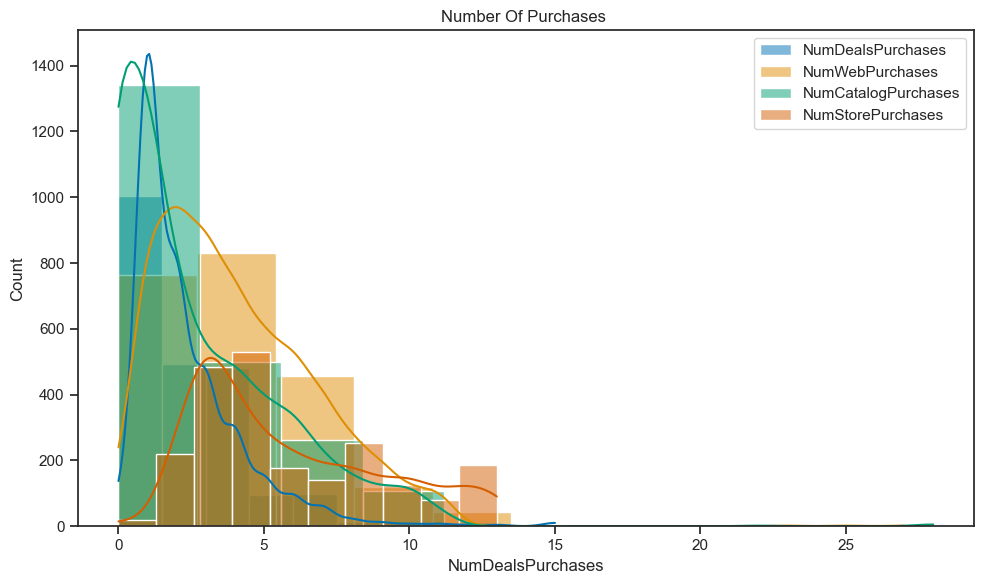

In [36]:
col= ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases',]
plt.figure(figsize=(10,6))
for i,col in enumerate(col):
  sns.histplot(data=df, x=df[col], bins=10, kde=True, label=col)
  plt.title("Number Of Purchases ")
plt.legend()
plt.tight_layout()
plt.show()

* Most people purchase 0-5 items from deals, most deals purchases come in at 1
* 0-10 with a peak at 2 items purchased on web
* 0-5 catalog purchases were mostly made
* 3-10 store purchases were mostly made with a peak at 3

In [37]:
df.groupby('NumWebPurchases')['NumWebVisitsMonth'].agg(['mean','sum', 'count']).reset_index().head()

,NumWebPurchases,mean,sum,count
0,0,5.979167,287,48
1,1,6.232759,2169,348
2,2,5.714674,2103,368
3,3,5.131737,1714,334
4,4,4.104693,1137,277


> People with the highest number of web visit tends to only make 1 purchase from the web

In [38]:
df.Complain.value_counts()/ len(df) * 100

Complain
0    99.052347
1     0.947653
Name: count, dtype: float64

> less than 1% of the distribution isssued complaints

In [39]:
age_by_complain=df[df['Complain']== 1]
age_by_complain=age_by_complain[['age','Complain']].value_counts().reset_index().sort_values('count', ascending=False)
age_by_complain.head()

,age,Complain,count
0,67,1,3
2,48,1,2
1,72,1,2
10,38,1,1
15,42,1,1


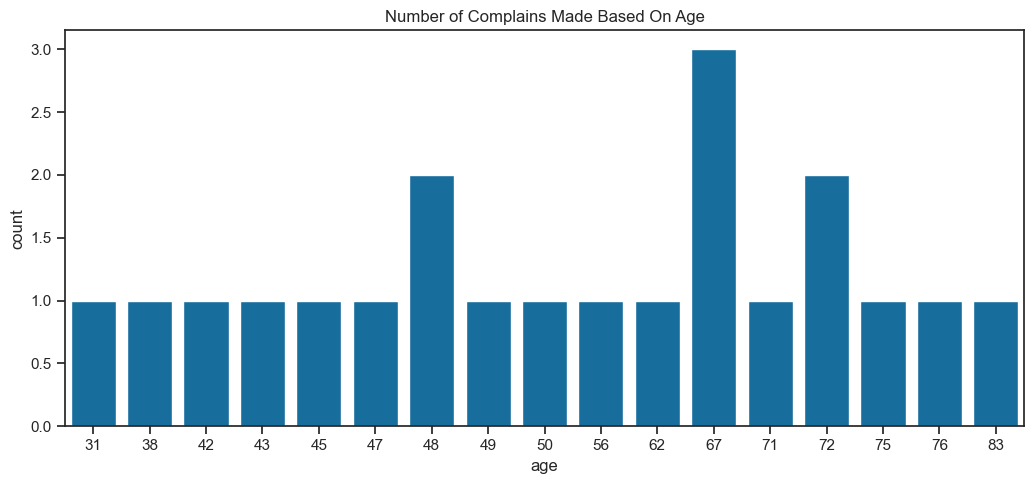

In [40]:
plt.figure(figsize=(10.5,5))

sns.barplot(data=age_by_complain, x='age', y='count')


plt.title('Number of Complains Made Based On Age')
plt.tight_layout()
plt.show()

> Out of those who made complaints  people aged between 46 and 72 makes the most

In [41]:
df.groupby('Children')['amount_spent'].agg(['mean','sum','count'])

,mean,sum,count
Children,,,
0,1105.248025,699622,633
1,474.700090,530240,1117
2,246.735577,102642,416
3,255.500000,12775,50


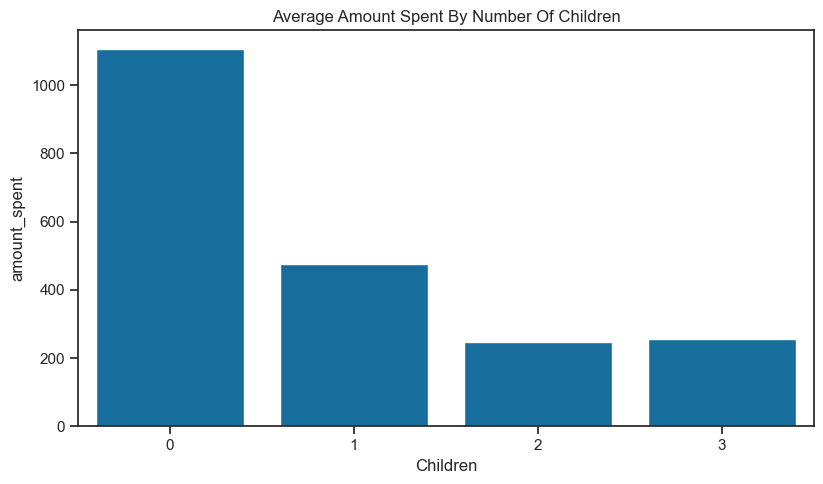

In [42]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'Children', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Number Of Children')
plt.tight_layout()
plt.show()

> As seen earlier, people with 0 children spends the most 

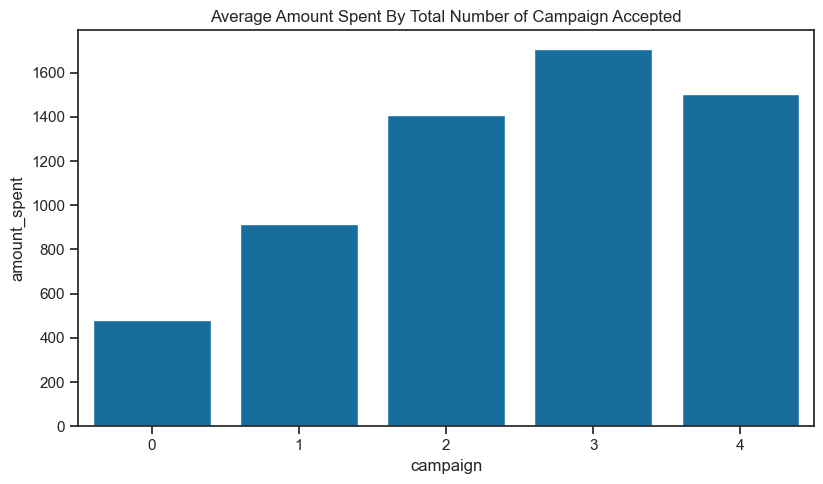

In [43]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'campaign', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Total Number of Campaign Accepted')
plt.tight_layout()
plt.show()

> People who accepted 3 campaign spends the most

In [44]:
df.groupby('Education')['amount_spent'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,494.930000,200,98986
1,Basic,81.796296,54,4417
2,Graduation,621.686380,1116,693802
3,Master,609.767123,365,222565
4,PhD,676.733888,481,325509


> People with graduation dominated the distribution but people with phd spend the most

In [45]:
df.groupby('Education')['Income'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,47633.190000,200,9526638.0
1,Basic,20306.259259,54,1096538.0
2,Graduation,51982.388441,1116,58012345.5
3,Master,52626.160274,365,19208548.5
4,PhD,55247.515593,481,26574055.0


> Phd holders earns the most followed by people with masters

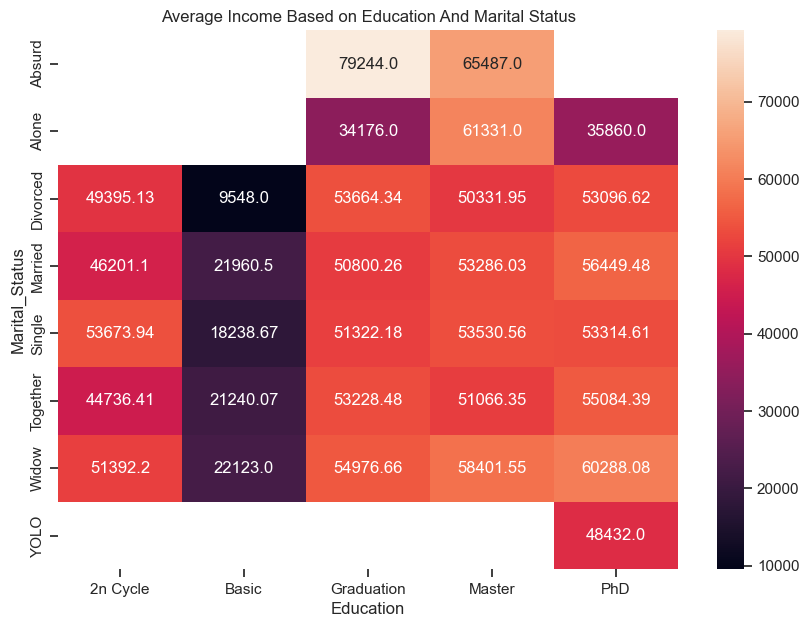

In [46]:
income=df.pivot_table(values='Income',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(10,7))
sns.heatmap(round(income,2), annot=True, fmt='')
plt.title("Average Income Based on Education And Marital Status")
plt.show()

> people with both graduation and absurd relationship status tends to earn the most while people with basic education earns the least amount of money regardless of their marital status

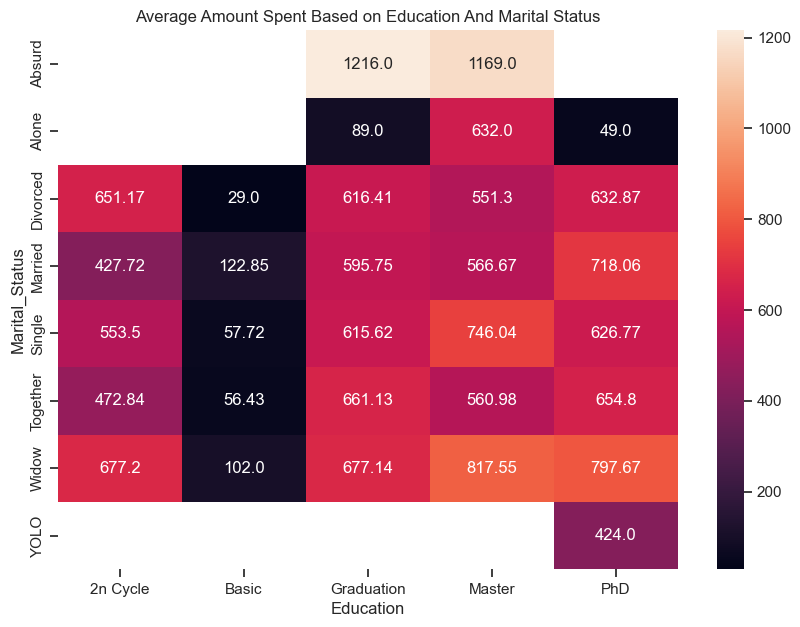

In [47]:
amount_spent=df.pivot_table(values='amount_spent',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(10,7))
sns.heatmap(round(amount_spent,2), annot=True, fmt='')
plt.title("Average Amount Spent Based on Education And Marital Status")
plt.show()

> People with Absurd relationship status with graduation or masters rank 1st and 2nd in money spent

In [48]:
df.groupby('Education')[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases']].agg(['mean', 'count', 'sum'])

NumDealsPurchases             NumWebPurchases              \
                        mean count   sum            mean count   sum   
Education                                                              
2n Cycle            2.260000   200   452        3.765000   200   753   
Basic               1.796296    54    97        1.888889    54   102   
Graduation          2.311828  1116  2580        4.115591  1116  4593   
Master              2.424658   365   885        4.035616   365  1473   
PhD                 2.359667   481  1135        4.432432   481  2132   

           NumCatalogPurchases             NumStorePurchases              
                          mean count   sum              mean count   sum  
Education                                                                 
2n Cycle              2.355000   200   471          5.560000   200  1112  
Basic                 0.481481    54    26          2.851852    54   154  
Graduation            2.738351  1116  3056          5.841398  1116  6519  
Master                2.545205   365   929          5.887671   365  2149  
PhD                   2.987526   481  1437          6.072765   481  2921

> Most customers tends to by from the store and web

In [49]:
df['purchases']= df.NumCatalogPurchases + df.NumDealsPurchases + df.NumStorePurchases + df.NumWebPurchases

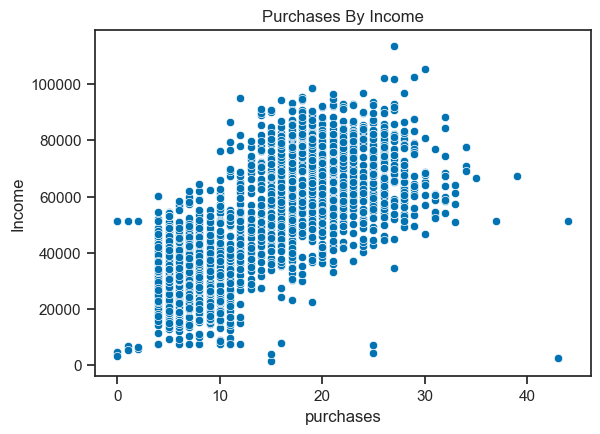

In [50]:
plt.figure(figsize=(6.4,4.5))

sns.scatterplot(data=df, x='purchases', y='Income')

plt.title('Purchases By Income')
plt.show()

> Increase in income means increase in number of purchases

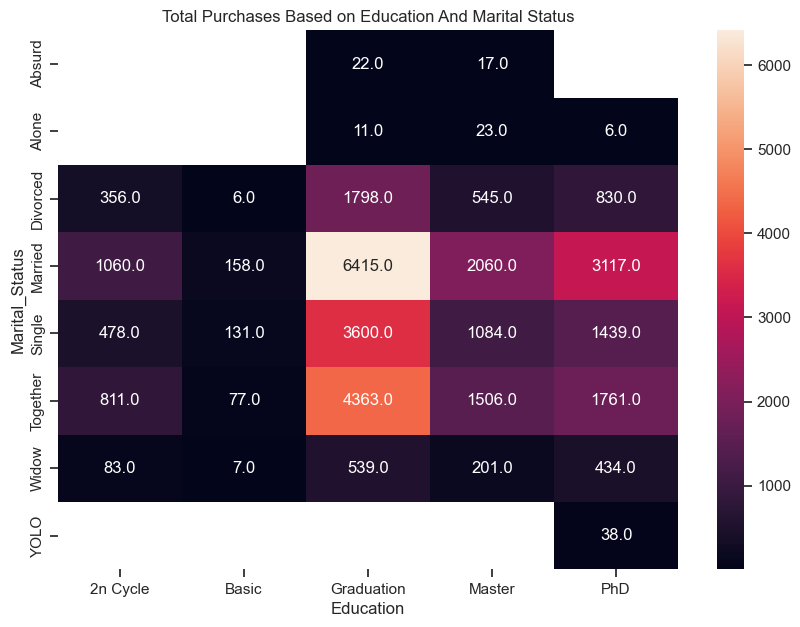

In [51]:
amount_spent=df.pivot_table(values='purchases',columns='Education',index='Marital_Status', aggfunc='sum')
plt.figure(figsize=(10,7))
sns.heatmap(round(amount_spent,2), annot=True, fmt='')
plt.title("Total Purchases Based on Education And Marital Status")
plt.show()

> People with graduation and are married makes the most purchase

In [52]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'age', 'Children', 'amount_spent', 'campaign', 'purchases'],
      dtype='object')

In [53]:
df=df[['age','Education', 'Marital_Status', 'Income','amount_spent','purchases','NumWebVisitsMonth','campaign']]

In [54]:
df.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,Graduation,Single,58138.0,1617,25,7,0
1,72,Graduation,Single,46344.0,27,6,5,0
2,61,Graduation,Together,71613.0,776,21,4,0
3,42,Graduation,Together,26646.0,53,8,6,0
4,45,PhD,Married,58293.0,422,19,5,0


In [59]:
df.to_csv(r'C:\Users\MINE\Desktop\Customer Segmentation\data\df.csv')

In [56]:
df.describe()

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,57.081227,51632.727888,607.075361,14.880866,5.319043,0.298285
std,11.692358,20675.942580,602.900476,7.670957,2.425359,0.679209
min,30.000000,1730.000000,5.000000,0.000000,0.000000,0.000000
25%,49.000000,35303.000000,69.000000,8.000000,3.000000,0.000000
50%,56.000000,51377.250000,396.500000,15.000000,6.000000,0.000000
75%,67.000000,68179.500000,1048.000000,21.000000,7.000000,0.000000
max,86.000000,113734.000000,2525.000000,44.000000,20.000000,4.000000


In [57]:
corr= df.select_dtypes(include=np.number).corr()

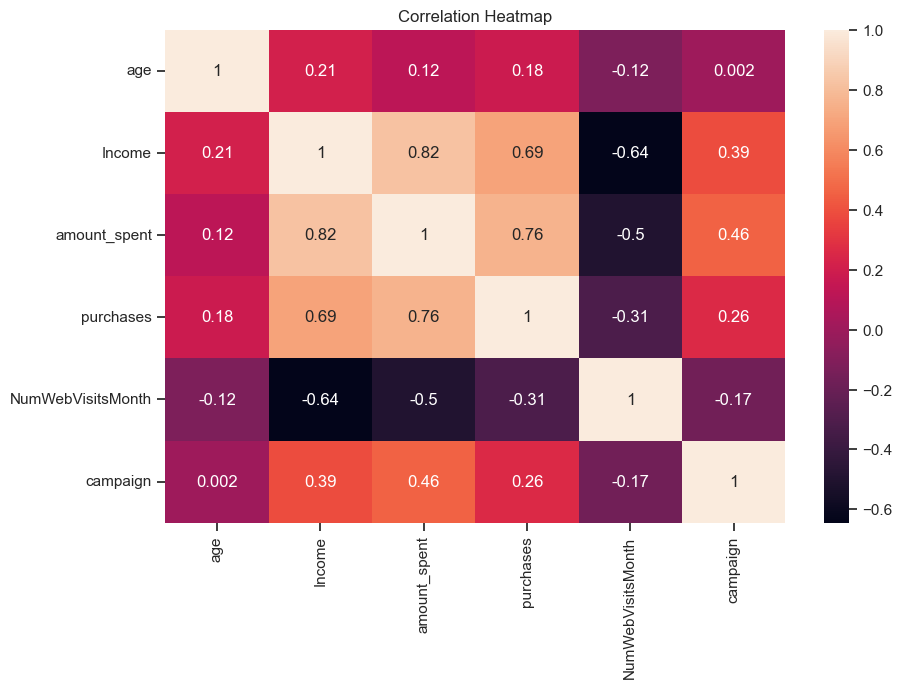

In [58]:
plt.figure(figsize=(10,6.4))


sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap')
plt.show()

# Preprocessing

In [65]:
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,3,4,58138.0,1617,25,7,0
1,72,3,4,46344.0,27,6,5,0
2,61,3,2,71613.0,776,21,4,0
3,42,3,2,26646.0,53,8,6,0
4,45,1,1,58293.0,422,19,5,0


In [66]:
df1.isnull().sum()

age                  0
Education            0
Marital_Status       0
Income               0
amount_spent         0
purchases            0
NumWebVisitsMonth    0
campaign             0
dtype: int64

In [67]:
# Scaling

scale= StandardScaler()
x= scale.fit_transform(df1)

In [68]:
x

array([[ 1.01959441,  0.45773285,  1.35002882, ...,  1.31944644,
         0.69323197, -0.43926491],
       [ 1.27623017,  0.45773285,  1.35002882, ..., -1.15798724,
        -0.1315745 , -0.43926491],
       [ 0.33523239,  0.45773285, -0.20287223, ...,  0.79788146,
        -0.54397773, -0.43926491],
       ...,
       [-1.03349166,  0.45773285,  0.5735783 , ...,  0.53709896,
         0.28082874,  1.03336905],
       [ 1.10513966, -0.53769011, -0.20287223, ...,  1.05866395,
        -0.95638097, -0.43926491],
       [ 1.27623017, -1.53311308, -0.97932275, ..., -0.50603101,
         0.69323197, -0.43926491]])

In [90]:
pca= PCA(n_components=2)
pca.fit(x)

PCA(n_components=2)

In [91]:
pca.explained_variance_ratio_

array([0.39690107, 0.14406762])

In [93]:
x_pca= pca.transform(x)

In [94]:
scores= []
inertia= []

for i in range(2,11):
  model= KMeans(n_clusters=i, n_init=10, max_iter=300, init='k-means++', random_state= 42)
  labels = model.fit_predict(x)
  score=silhouette_score(x,labels)
  scores.append(score)
  inertia.append(model.inertia_)

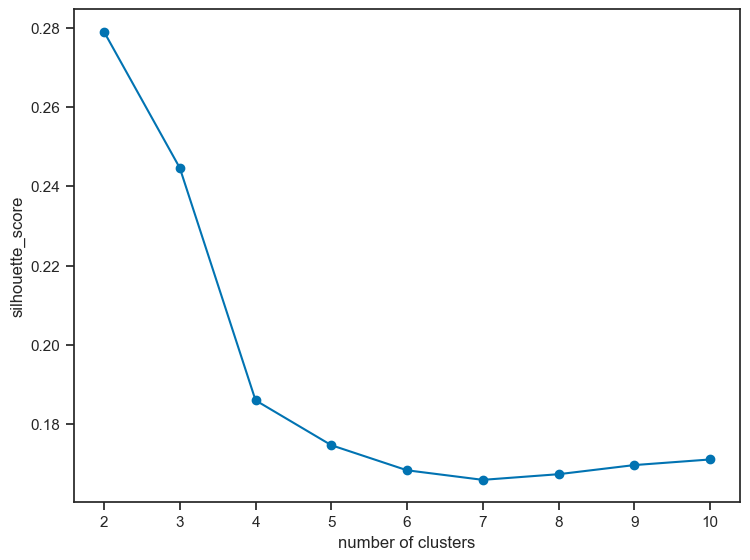

In [95]:
plt.figure(figsize=(8.6,6.4))
plt.plot(list(range(2,11)),scores, marker= 'o')

plt.xlabel('number of clusters')
plt.ylabel('silhouette_score')
plt.show()

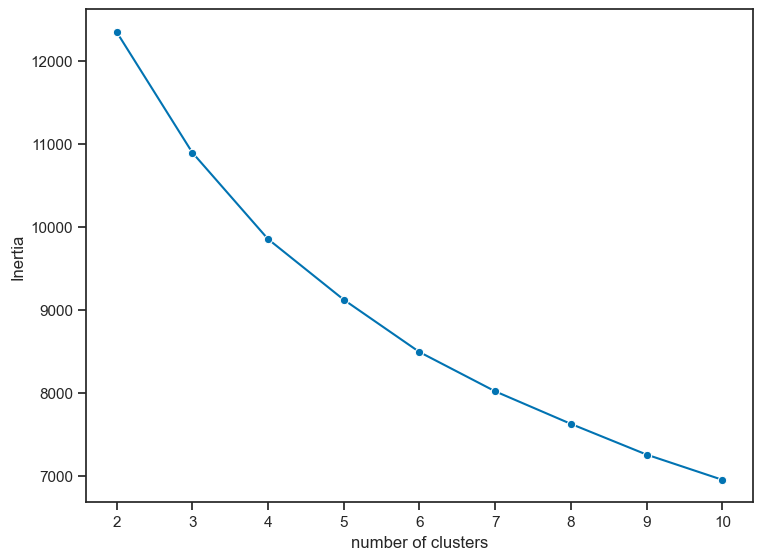

In [97]:
plt.figure(figsize=(8.6,6.4))
sns.lineplot(x=list(range(2,11)), y= inertia, marker='o')


plt.xlabel('number of clusters')
plt.ylabel('Inertia')
plt.show()
plt.show()

In [98]:
final_model= KMeans(n_clusters=5, max_iter=100, n_init=10, random_state=42, init='k-means++').fit(x)

In [99]:
df['Cluster']= final_model.predict(x)

In [100]:
df['Cluster'].value_counts()

Cluster
3    650
4    568
0    502
2    347
1    149
Name: count, dtype: int64

In [224]:
centriod= final_model.cluster_centers_
cluster_original= scale.inverse_transform(centriod)

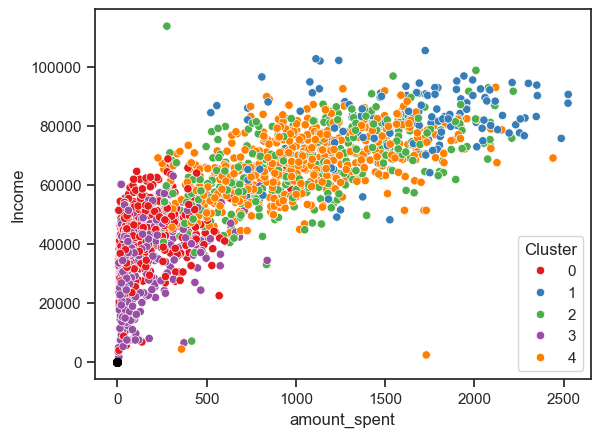

In [ ]:
plt.Figure(figsize=(6.4,4.6))

sns.scatterplot(x='amount_spent', y='Income', data=df, hue='Cluster', palette='Set1')


plt.show()

In [138]:
df['x'], df['y']= x_pca[:,0],x_pca[:,1]

In [ ]:

centriod= pca.transform(centriod)
centriod

array([[-0.98599617,  1.00442717],
       [ 3.11797532, -1.20393143],
       [ 1.33263764,  0.26905606],
       [-1.8358967 , -0.6741678 ],
       [ 1.34343994,  0.03305102]])

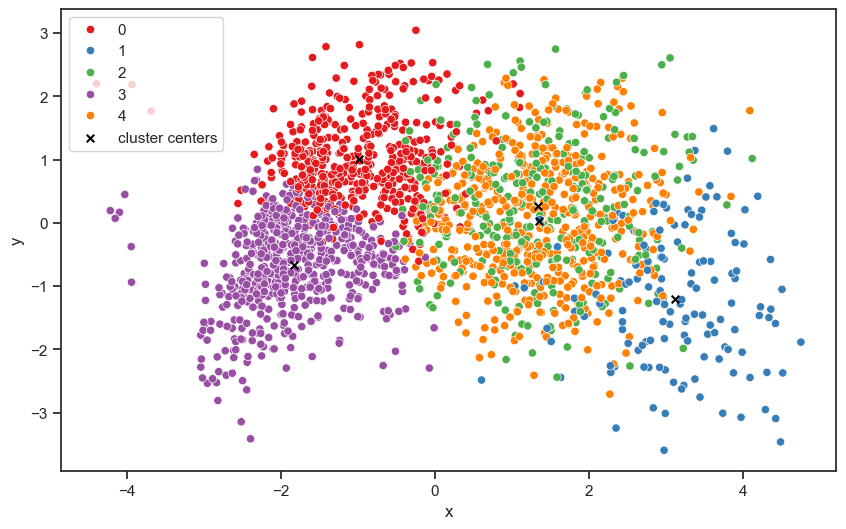

In [222]:
plt.figure(figsize=(10,6))

sns.scatterplot(x='x', y='y', data=df, hue='Cluster', palette='Set1')

plt.scatter(centriod[:,0], centriod[:,1], color= 'black',s=30, marker='x', label='cluster centers')

plt.legend(loc= 'best')
plt.show()

In [141]:
features= df.drop(columns=['Cluster', 'Education', 'Marital_Status']).columns
cluster_features= df.groupby('Cluster')[features].mean()

In [142]:
round(cluster_features, 2)

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign,x,y
Cluster,,,,,,,,
0,62.47,41264.32,161.16,9.78,6.17,0.13,-0.99,1.00
1,54.90,81069.52,1634.79,21.03,3.41,2.31,3.11,-1.21
2,60.08,66604.42,1056.22,20.90,4.19,0.23,1.33,0.27
3,49.38,31382.69,113.26,8.31,6.83,0.07,-1.84,-0.67
4,59.86,67101.40,1022.31,21.62,4.03,0.22,1.34,0.04


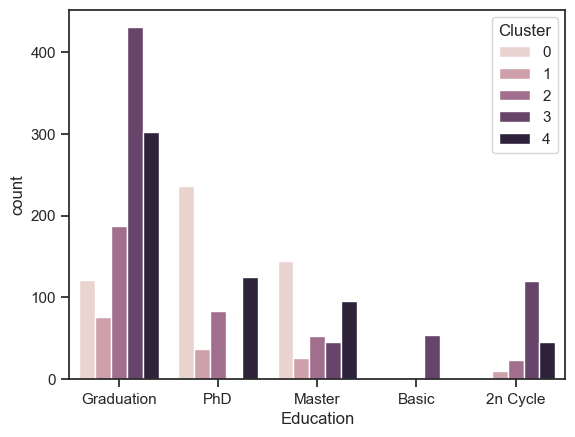

In [143]:
sns.countplot(data=df, x='Education', hue='Cluster')

plt.show()

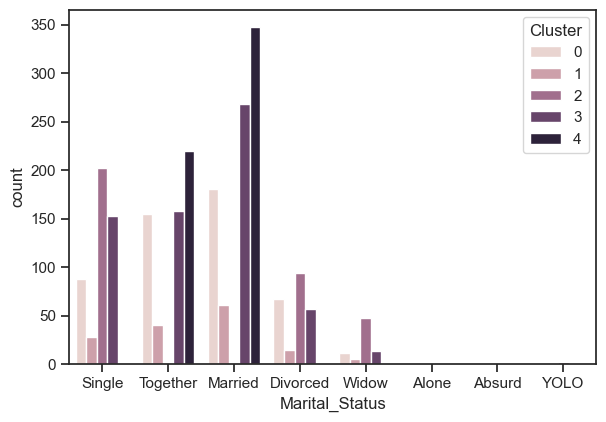

In [144]:
plt.figure(figsize=(6.8,4.6))
sns.countplot(data=df, x='Marital_Status', hue='Cluster')

plt.show()

In [145]:
df[['Cluster','Marital_Status','Education']].value_counts().unstack(-1)

Education               2n Cycle  Basic  Graduation  Master   PhD
Cluster Marital_Status                                           
0       Alone                NaN    NaN         NaN     NaN   1.0
        Divorced             NaN    NaN        18.0    20.0  29.0
        Married              NaN    NaN        36.0    49.0  95.0
        Single               NaN    NaN        16.0    26.0  46.0
        Together             NaN    NaN        48.0    48.0  59.0
        Widow                NaN    NaN         3.0     2.0   6.0
1       Absurd               NaN    NaN         1.0     NaN   NaN
        Divorced             2.0    NaN         8.0     1.0   3.0
        Married              4.0    NaN        27.0    10.0  20.0
        Single               3.0    NaN        13.0     6.0   6.0
        Together             1.0    NaN        25.0     7.0   7.0
        Widow                NaN    NaN         2.0     2.0   1.0
2       Absurd               NaN    NaN         NaN     1.0   NaN
        Alone                NaN    NaN         NaN     1.0   NaN
        Divorced             9.0    NaN        52.0    13.0  20.0
        Single              12.0    NaN       115.0    31.0  44.0
        Widow                3.0    NaN        20.0     7.0  17.0
        YOLO                 NaN    NaN         NaN     NaN   2.0
3       Alone                NaN    NaN         1.0     NaN   NaN
        Divorced            12.0    1.0        41.0     3.0   NaN
        Married             51.0   20.0       179.0    18.0   NaN
        Single              21.0   18.0       102.0    12.0   NaN
        Together            34.0   14.0        97.0    13.0   NaN
        Widow                2.0    1.0        10.0     NaN   NaN
4       Married             25.0    NaN       187.0    61.0  75.0
        Together            21.0    NaN       115.0    34.0  50.0

> INSIGHT

* Cluster 4  they make the most purchases and are married.
* Clusrer 1  they make the most Income and spends the most, they make the second highest purchases and they accepted campaign the most
* Cluster 3 youngest in age, lowest Income erners,spenders as well as purchases, most are married and graduation holders and they visit the web the most while taking the lowest campaign
* Cluster 2 they rank second oldest and are mostly single,most are graduation holders
* Cluster 0 are the oldest in the group, they rank second lowest in Income,amount_spent and purchases,they have the highest number of phd and masters holders

In [233]:
# minimum samples >= number of features + 1

min_samples= len(df1.columns) + 1
min_samples

9

In [237]:
nn= NearestNeighbors(n_neighbors= min_samples, metric='euclidean')
nn.fit(x)

NearestNeighbors(metric='euclidean', n_neighbors=9)

In [238]:
distance,index= nn.kneighbors(x)
distance= np.sort(distance[:,-1])

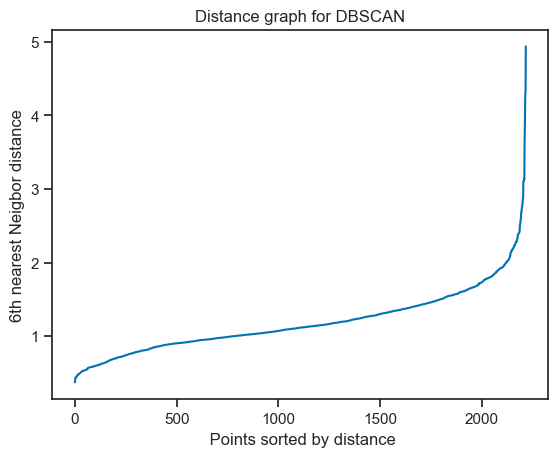

In [247]:
plt.plot(distance)

plt.xlabel(' Points sorted by distance')
plt.ylabel('6th nearest Neigbor distance')
plt.title('Distance graph for DBSCAN')

plt.show()

In [255]:
db= DBSCAN(eps=1.2, min_samples=9)
db.fit(x)

DBSCAN(eps=1.2, min_samples=9)

In [256]:
np.unique(db.labels_)

array([-1,  0,  1,  2,  3,  4,  5], dtype=int64)

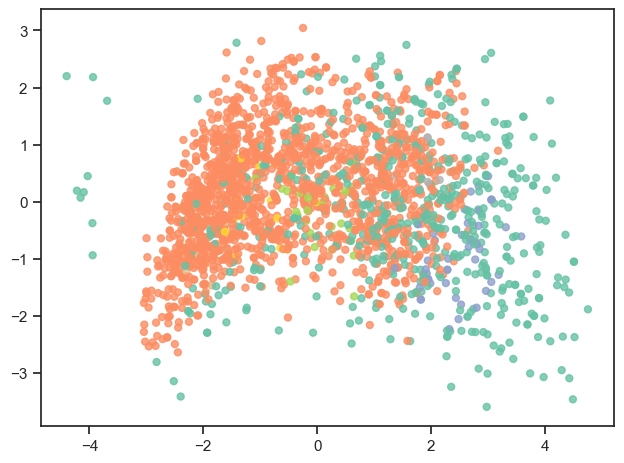

In [278]:


scatter= plt.scatter(df['x'], df['y'], c= db.labels_ , cmap='Set2', s=25, alpha=0.8)


plt.tight_layout()

plt.show()

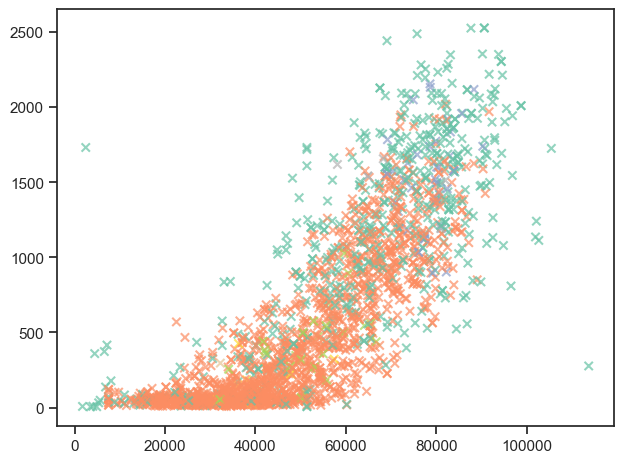

In [280]:


plt.scatter(df['Income'], df['amount_spent'], c= db.labels_,cmap='Set2', marker='x', alpha=0.7,)

plt.tight_layout()

plt.show()

In [188]:
df1.columns

Index(['age', 'Education', 'Marital_Status', 'Income', 'amount_spent',
       'purchases', 'NumWebVisitsMonth', 'campaign'],
      dtype='object')

In [134]:
joblib.dump(final_model,"model\\model.pkl")

FileNotFoundError: [Errno 2] No such file or directory: 'model\\model.pkl'

In [ ]:
joblib.dump(scale,"model\\scale.pkl")

['model\\scale.pkl']

In [77]:
df.to_csv("data\\clustered.csv")